In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [2]:
import pickle
import numpy as np
from sklearn.preprocessing import LabelEncoder

with open('splits.pkl', 'rb') as f:
    splits = pickle.load(f)

X_train_nn = splits['X_train']
X_val_nn   = splits['X_val']
X_test_nn  = splits['X_test']
y_train_nn = splits['y_train'].astype(int)
y_val_nn   = splits['y_val'].astype(int)
y_test_nn  = splits['y_test'].astype(int)

X_train_dense = X_train_nn.toarray().astype(np.float32)
X_val_dense   = X_val_nn.toarray().astype(np.float32)
X_test_dense  = X_test_nn.toarray().astype(np.float32)

n_features = X_train_dense.shape[1]
print(f"Input dimensionality: {n_features} features")
print(f"Train: {X_train_dense.shape}, Val: {X_val_dense.shape}, Test: {X_test_dense.shape}")

Input dimensionality: 11728 features
Train: (53797, 11728), Val: (17933, 11728), Test: (17933, 11728)


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
 
def build_mlp(input_dim, hidden_units=256, dropout_rate=0.3, learning_rate=0.001):
    """
    MLP Architecture rationale:
    Input layer: n_features neurons (one per TF-IDF dimension)
    Hidden layer 1 (256): captures high-level patterns; ReLU avoids vanishing gradients
    BatchNormalization: stabilises and accelerates training
    Dropout (0.3): regularisation — prevents overfitting on 89k samples
    Hidden layer 2 (128): refines representations at lower dimensionality
    Output layer (1): single sigmoid neuron for binary classification
    """
    model = Sequential([
        Dense(hidden_units, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(dropout_rate),
        Dense(hidden_units // 2, activation='relu'),
        BatchNormalization(),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

mlp_baseline = build_mlp(n_features)
mlp_baseline.summary()
 
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
 
history_mlp = mlp_baseline.fit(
    X_train_dense, y_train_nn,
    validation_data=(X_val_dense, y_val_nn),
    epochs=20,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)
 
#evaluate on validation set
mlp_val_loss, mlp_val_acc = mlp_baseline.evaluate(X_val_dense, y_val_nn, verbose=0)
print(f"\nBaseline MLP — Val Accuracy: {mlp_val_acc:.4f}, Val Loss: {mlp_val_loss:.4f}")

A:\Anaconda\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     3,002,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,037,185 (11.59 MB)

 Trainable params: 3,036,417 (11.58 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.8898 - loss: 0.3213 - val_accuracy: 0.9019 - val_loss: 0.5611
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9476 - loss: 0.1759 - val_accuracy: 0.9246 - val_loss: 0.3801
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9648 - loss: 0.1149 - val_accuracy: 0.9214 - val_loss: 0.2606
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9764 - loss: 0.0751 - val_accuracy: 0.9177 - val_loss: 0.3302
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9834 - loss: 0.0537 - val_accuracy: 0.9184 - val_loss: 0.3918
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9871 - loss: 0.0416 - val_accuracy: 0.9160 - val_loss: 0.4226

Baseline MLP — Val Accuracy: 0.9214, Val Loss: 0.2606


In [4]:
import gc

tuning_results = []

dropout_rates     = [0.2, 0.3, 0.5]
hidden_units_list = [128, 256, 512]
learning_rates    = [0.0001, 0.001, 0.01]


print("Tuning: Dropout Rate")
for dr in dropout_rates:
    tf.keras.backend.clear_session()
    m = build_mlp(n_features, hidden_units=256, dropout_rate=dr, learning_rate=0.001)
    m.fit(X_train_dense, y_train_nn,
          validation_data=(X_val_dense, y_val_nn),
          epochs=20, batch_size=256,
          callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
          verbose=0)
    _, val_acc = m.evaluate(X_val_dense, y_val_nn, verbose=0)
    print(f"  dropout={dr} → val_acc={val_acc:.4f}")
    tuning_results.append({'param': 'dropout_rate', 'value': dr, 'val_acc': val_acc})
    del m; gc.collect()


print("\nTuning: Hidden Units")
for hu in hidden_units_list:
    tf.keras.backend.clear_session()
    m = build_mlp(n_features, hidden_units=hu, dropout_rate=0.3, learning_rate=0.001)
    m.fit(X_train_dense, y_train_nn,
          validation_data=(X_val_dense, y_val_nn),
          epochs=20, batch_size=256,
          callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
          verbose=0)
    _, val_acc = m.evaluate(X_val_dense, y_val_nn, verbose=0)
    print(f"  hidden_units={hu} → val_acc={val_acc:.4f}")
    tuning_results.append({'param': 'hidden_units', 'value': hu, 'val_acc': val_acc})
    del m; gc.collect()


print("\nTuning: Learning Rate")
for lr in learning_rates:
    tf.keras.backend.clear_session()
    m = build_mlp(n_features, hidden_units=256, dropout_rate=0.3, learning_rate=lr)
    m.fit(X_train_dense, y_train_nn,
          validation_data=(X_val_dense, y_val_nn),
          epochs=20, batch_size=256,
          callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
          verbose=0)
    _, val_acc = m.evaluate(X_val_dense, y_val_nn, verbose=0)
    print(f"  learning_rate={lr} → val_acc={val_acc:.4f}")
    tuning_results.append({'param': 'learning_rate', 'value': lr, 'val_acc': val_acc})
    del m; gc.collect()

Tuning: Dropout Rate

  dropout=0.2 → val_acc=0.9165
  dropout=0.3 → val_acc=0.9127
  dropout=0.5 → val_acc=0.9227

Tuning: Hidden Units
  hidden_units=128 → val_acc=0.9221
  hidden_units=256 → val_acc=0.9113
  hidden_units=512 → val_acc=0.9119

Tuning: Learning Rate
  learning_rate=0.0001 → val_acc=0.9239
  learning_rate=0.001 → val_acc=0.9190
  learning_rate=0.01 → val_acc=0.9135


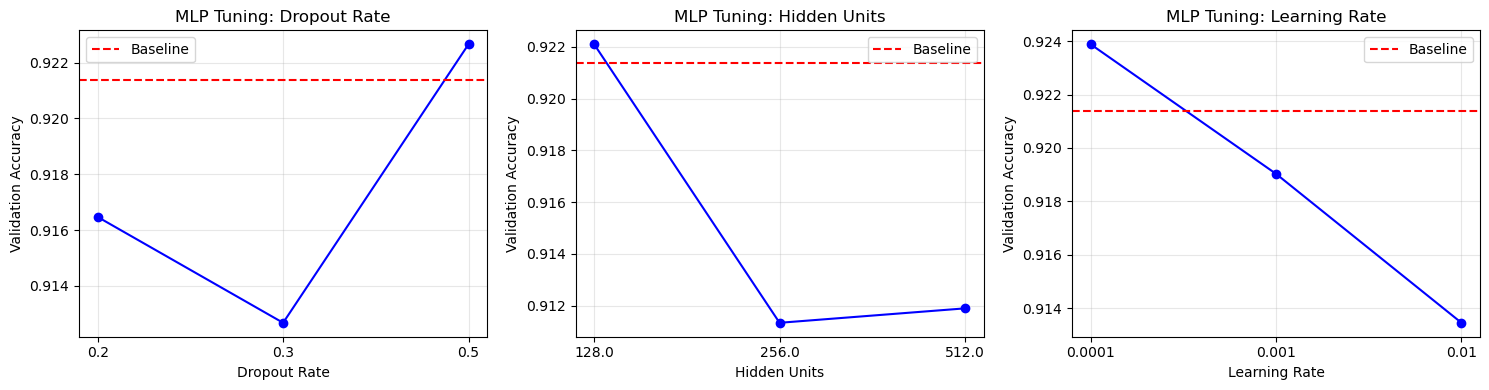

In [5]:
import pandas as pd
 
results_df = pd.DataFrame(tuning_results)
 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
params = ['dropout_rate', 'hidden_units', 'learning_rate']
titles = ['Dropout Rate', 'Hidden Units', 'Learning Rate']
 
for ax, param, title in zip(axes, params, titles):
    subset = results_df[results_df['param'] == param]
    ax.plot(subset['value'].astype(str), subset['val_acc'], marker='o', color='blue')
    ax.axhline(mlp_val_acc, color='red', linestyle='--', label='Baseline')
    ax.set_title(f'MLP Tuning: {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Validation Accuracy')
    ax.legend()
    ax.grid(alpha=0.3)
 
plt.tight_layout()
plt.savefig('mlp_tuning_results.png', dpi=150)
plt.show()

A:\Anaconda\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7440 - loss: 0.5572 - val_accuracy: 0.8646 - val_loss: 0.6258
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8876 - loss: 0.3127 - val_accuracy: 0.9144 - val_loss: 0.4317
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9181 - loss: 0.2463 - val_accuracy: 0.9186 - val_loss: 0.2775
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9336 - loss: 0.2066 - val_accuracy: 0.9218 - val_loss: 0.2618
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9429 - loss: 0.1797 - val_accuracy: 0.9226 - val_loss: 0.2659
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9519 - loss: 0.1523 - val_accuracy: 0.9225 - val_loss: 0.2715
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9593 - loss: 0.1309 - val_accuracy: 0.9201 - val_loss: 0.2779
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9637 - loss: 0.1154 - val_accu

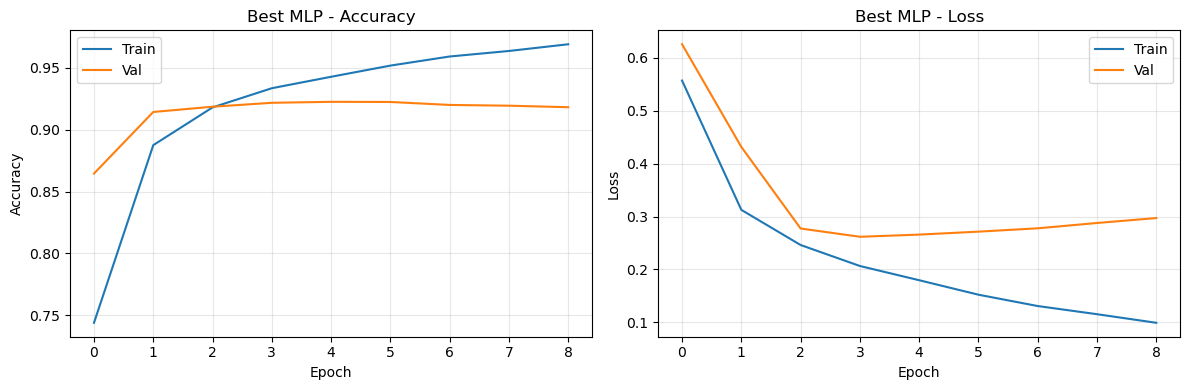

In [6]:
BEST_DROPOUT = 0.2
BEST_HIDDEN  = 512
BEST_LR      = 0.0001
 
tf.keras.backend.clear_session()
mlp_best = build_mlp(n_features, BEST_HIDDEN, BEST_DROPOUT, BEST_LR)
 
history_mlp_best = mlp_best.fit(
    X_train_dense, y_train_nn,
    validation_data=(X_val_dense, y_val_nn),
    epochs=30,
    batch_size=256,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=1
)
 
# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_mlp_best.history['accuracy'], label='Train')
plt.plot(history_mlp_best.history['val_accuracy'], label='Val')
plt.title('Best MLP - Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
 
plt.subplot(1, 2, 2)
plt.plot(history_mlp_best.history['loss'], label='Train')
plt.plot(history_mlp_best.history['val_loss'], label='Val')
plt.title('Best MLP - Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('mlp_best_training_curves.png', dpi=150)
plt.show()

561/561 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Best MLP - Test Set Evaluation
              precision    recall  f1-score   support

Fake (False)       0.93      0.94      0.93     10272
 Real (True)       0.91      0.90      0.91      7661

    accuracy                           0.92     17933
   macro avg       0.92      0.92      0.92     17933
weighted avg       0.92      0.92      0.92     17933

Training Accuracy: 0.9599
Test Accuracy:     0.9226


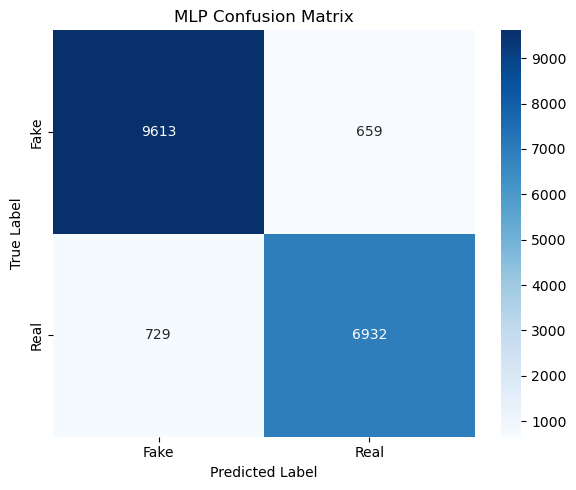

MLP saved to mlp_best_model.keras


In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
 
y_pred_mlp = (mlp_best.predict(X_test_dense) > 0.5).astype(int).flatten()
 
print("Best MLP - Test Set Evaluation")
print(classification_report(y_test_nn, y_pred_mlp, target_names=['Fake (False)', 'Real (True)']))
 
_, mlp_train_acc = mlp_best.evaluate(X_train_dense, y_train_nn, verbose=0)
_, mlp_test_acc  = mlp_best.evaluate(X_test_dense,  y_test_nn,  verbose=0)
print(f"Training Accuracy: {mlp_train_acc:.4f}")
print(f"Test Accuracy:     {mlp_test_acc:.4f}")
 
cm = confusion_matrix(y_test_nn, y_pred_mlp)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title('MLP Confusion Matrix')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('mlp_confusion_matrix.png', dpi=150)
plt.show()
 
mlp_best.save('mlp_best_model.keras')
print("MLP saved to mlp_best_model.keras")
del mlp_best, X_train_dense, X_val_dense, X_test_dense
gc.collect()
tf.keras.backend.clear_session()

In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

In [9]:
# from sklearn.decomposition import TruncatedSVD
# svd = TruncatedSVD(n_components=128, random_state=1)
# X_train_svd = svd.fit_transform(X_train_nn)  # sparse in, small dense out
# X_val_svd   = svd.transform(X_val_nn)
# X_test_svd  = svd.transform(X_test_nn)

# print(f"Explained variance retained: {svd.explained_variance_ratio_.sum():.4f}")

# cnn_n_features = X_train_svd.shape[1]
# X_train_cnn = X_train_svd.reshape(-1, cnn_n_features, 1).astype(np.float32)
# X_val_cnn   = X_val_svd.reshape(-1, cnn_n_features, 1).astype(np.float32)
# X_test_cnn  = X_test_svd.reshape(-1, cnn_n_features, 1).astype(np.float32)
# del X_train_svd, X_val_svd, X_test_svd
# gc.collect()

from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalAveragePooling1D

# convert sparse to dense directly in smaller batches, then slice features
# use only first 128 features instead of SVD decomposition
X_train_cnn = X_train_nn[:, :128].toarray().reshape(-1, 128, 1).astype(np.float32)
X_val_cnn   = X_val_nn[:, :128].toarray().reshape(-1, 128, 1).astype(np.float32)
X_test_cnn  = X_test_nn[:, :128].toarray().reshape(-1, 128, 1).astype(np.float32)

cnn_n_features = 128
print(f"CNN input shape: {X_train_cnn.shape}")

print(f"CNN input shape: {X_train_cnn.shape}")

def build_cnn(input_dim, filters=64, kernel_size=5, dropout_rate=0.3, learning_rate=0.001):
    """
    DL CNN Architecture:
    Input: (128, 1) - SVD-reduced TF-IDF vector treated as 1D signal
    Conv1D(64, 5) -> detects local feature patterns across 5 adjacent dimensions
    MaxPooling1D(2) -> downsamples, retains strongest activations
    Conv1D(128, 3) -> detects higher-level compound patterns
    MaxPooling1D(2) -> further downsampling
    GlobalAveragePooling1D -> collapses spatial dimension to fixed vector
    Dense(64, ReLU) -> final non-linear classifier
    Dropout -> regularisation
    Dense(1, sigmoid) -> binary output
    """
    model = Sequential([
        Conv1D(filters, kernel_size, activation='relu', input_shape=(input_dim, 1)),
        MaxPooling1D(pool_size=2),
        Conv1D(filters * 2, 3, activation='relu'),
        MaxPooling1D(pool_size=2),
        GlobalAveragePooling1D(),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


tf.keras.backend.clear_session()
cnn_baseline = build_cnn(cnn_n_features)  #cnn_n_features = 128
cnn_baseline.summary()

history_cnn = cnn_baseline.fit(
    X_train_cnn, y_train_nn,
    validation_data=(X_val_cnn, y_val_nn),
    epochs=20,
    batch_size=256,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=1
)

cnn_val_loss, cnn_val_acc = cnn_baseline.evaluate(X_val_cnn, y_val_nn, verbose=0)
print(f"\nBaseline CNN - Val Accuracy: {cnn_val_acc:.4f}, Val Loss: {cnn_val_loss:.4f}")

del cnn_baseline
gc.collect()
tf.keras.backend.clear_session()

CNN input shape: (53797, 128, 1)
CNN input shape: (53797, 128, 1)


A:\Anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 60, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,409 (130.50 KB)

 Trainable params: 33,409 (130.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.5814 - loss: 0.6800 - val_accuracy: 0.5817 - val_loss: 0.6774
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5878 - loss: 0.6767 - val_accuracy: 0.5848 - val_loss: 0.6761
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5900 - loss: 0.6754 - val_accuracy: 0.5912 - val_loss: 0.6742
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5932 - loss: 0.6728 - val_accuracy: 0.5923 - val_loss: 0.6727
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5935 - loss: 0.6723 - val_accuracy: 0.5924 - val_loss: 0.6721
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5940 - loss: 0.6714 - val_accuracy: 0.5917 - val_loss: 0.6719
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5947 - loss: 0.6712 - val_accuracy: 0.5939 - val_loss: 0.6705
Epoch 8/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5947 - loss: 0.6709 - val_accu

In [10]:
def tune_cnn(input_dim, filters, kernel_size, dropout_rate,
             X_train, y_train, X_val, y_val):
    """
    Builds, trains and evaluates one CNN configuration, then immediately clears it from memory. Returns only val_acc.
    """
    tf.keras.backend.clear_session()  # destroys previous TF graph
    model = build_cnn(input_dim, filters, kernel_size, dropout_rate)
    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20, batch_size=256,
        callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
        verbose=0
    )
    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    del model
    gc.collect()
    return val_acc
 
cnn_tuning_results = []
 
print("Tuning: CNN filters")
for f in [32, 64, 128]:
    val_acc = tune_cnn(cnn_n_features, f, 5, 0.3,
                       X_train_cnn, y_train_nn, X_val_cnn, y_val_nn)
    print(f"  filters={f} -> val_acc={val_acc:.4f}")
    cnn_tuning_results.append({'param': 'filters', 'value': f, 'val_acc': val_acc})
 
print("\nTuning: CNN kernel_size")
for ks in [3, 5, 7]:
    val_acc = tune_cnn(cnn_n_features, 64, ks, 0.3,
                       X_train_cnn, y_train_nn, X_val_cnn, y_val_nn)
    print(f"  kernel_size={ks} -> val_acc={val_acc:.4f}")
    cnn_tuning_results.append({'param': 'kernel_size', 'value': ks, 'val_acc': val_acc})
 
print("\nTuning: CNN dropout_rate")
for dr in [0.2, 0.3, 0.5]:
    val_acc = tune_cnn(cnn_n_features, 64, 5, dr,
                       X_train_cnn, y_train_nn, X_val_cnn, y_val_nn)
    print(f"  dropout={dr} -> val_acc={val_acc:.4f}")
    cnn_tuning_results.append({'param': 'dropout_rate', 'value': dr, 'val_acc': val_acc})

Tuning: CNN filters
  filters=32 -> val_acc=0.5976
  filters=64 -> val_acc=0.5973
  filters=128 -> val_acc=0.5973

Tuning: CNN kernel_size
  kernel_size=3 -> val_acc=0.5951
  kernel_size=5 -> val_acc=0.5972
  kernel_size=7 -> val_acc=0.5968

Tuning: CNN dropout_rate
  dropout=0.2 -> val_acc=0.5971
  dropout=0.3 -> val_acc=0.5969
  dropout=0.5 -> val_acc=0.5971


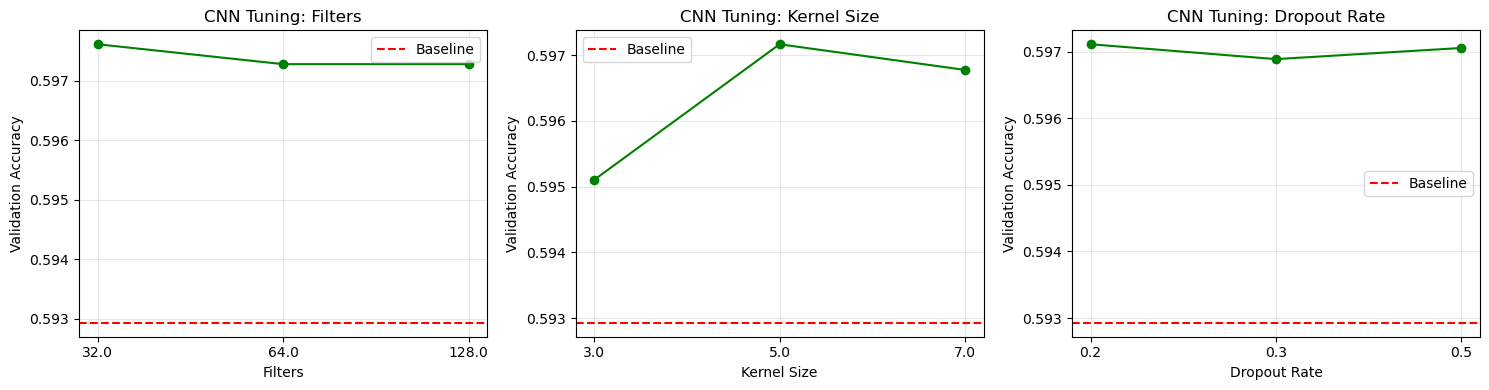

In [11]:
cnn_results_df = pd.DataFrame(cnn_tuning_results)
 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
params = ['filters', 'kernel_size', 'dropout_rate']
titles = ['Filters', 'Kernel Size', 'Dropout Rate']
 
for ax, param, title in zip(axes, params, titles):
    subset = cnn_results_df[cnn_results_df['param'] == param]
    ax.plot(subset['value'].astype(str), subset['val_acc'], marker='o', color='green')
    ax.axhline(cnn_val_acc, color='red', linestyle='--', label='Baseline')
    ax.set_title(f'CNN Tuning: {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Validation Accuracy')
    ax.legend()
    ax.grid(alpha=0.3)
 
plt.tight_layout()
plt.savefig('cnn_tuning_results.png', dpi=150)
plt.show()

Epoch 1/50


A:\Anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.5807 - loss: 0.6808 - val_accuracy: 0.5818 - val_loss: 0.6773
Epoch 2/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.5894 - loss: 0.6765 - val_accuracy: 0.5954 - val_loss: 0.6756
Epoch 3/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.5956 - loss: 0.6755 - val_accuracy: 0.5957 - val_loss: 0.6745
Epoch 4/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.5961 - loss: 0.6747 - val_accuracy: 0.5967 - val_loss: 0.6740
Epoch 5/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.5964 - loss: 0.6746 - val_accuracy: 0.5968 - val_loss: 0.6738
Epoch 6/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.5962 - loss: 0.6740 - val_accuracy: 0.5969 - val_loss: 0.6739
Epoch 7/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.5969 - loss: 0.6740 - val_accuracy: 0.5973 - val_loss: 0.6739
Epoch 8/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.5964 - loss: 0.6741 - val_accuracy: 0.596

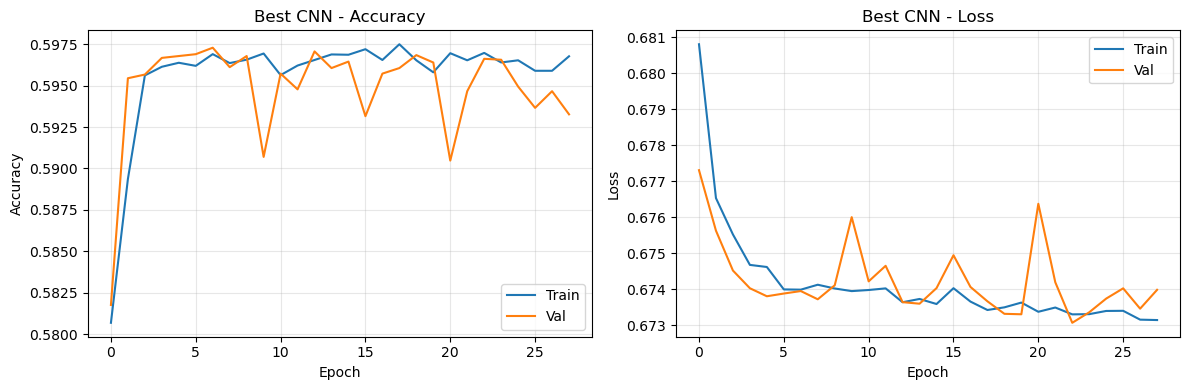

In [12]:
BEST_FILTERS     = 128   
BEST_KERNEL      = 7   
BEST_CNN_DROPOUT = 0.2
 
tf.keras.backend.clear_session()
cnn_best = build_cnn(cnn_n_features, BEST_FILTERS, BEST_KERNEL, BEST_CNN_DROPOUT)
 
history_cnn_best = cnn_best.fit(
    X_train_cnn, y_train_nn,
    validation_data=(X_val_cnn, y_val_nn),
    epochs=50,
    batch_size=256,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=1
)
 

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn_best.history['accuracy'], label='Train')
plt.plot(history_cnn_best.history['val_accuracy'], label='Val')
plt.title('Best CNN - Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
 
plt.subplot(1, 2, 2)
plt.plot(history_cnn_best.history['loss'], label='Train')
plt.plot(history_cnn_best.history['val_loss'], label='Val')
plt.title('Best CNN - Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('cnn_best_training_curves.png', dpi=150)
plt.show()

561/561 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Best CNN - Test Set Evaluation
              precision    recall  f1-score   support

Fake (False)       0.59      0.93      0.72     10272
 Real (True)       0.60      0.14      0.22      7661

    accuracy                           0.59     17933
   macro avg       0.59      0.53      0.47     17933
weighted avg       0.59      0.59      0.51     17933

Training Accuracy: 0.5969
Test Accuracy:     0.5915


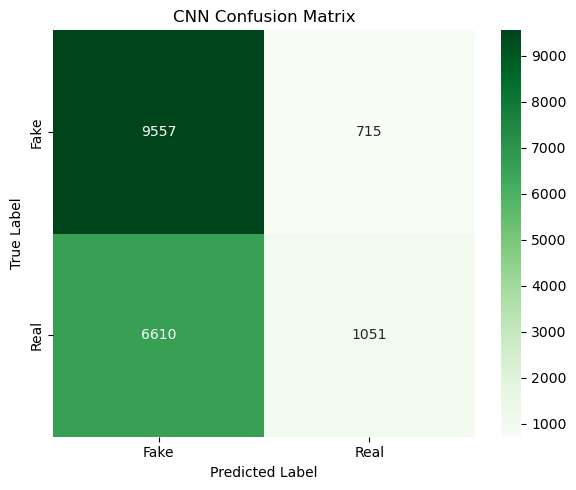

CNN saved to cnn_best_model.keras


In [13]:
y_pred_cnn = (cnn_best.predict(X_test_cnn) > 0.5).astype(int).flatten()
 
print("Best CNN - Test Set Evaluation")
print(classification_report(y_test_nn, y_pred_cnn, target_names=['Fake (False)', 'Real (True)']))
 
_, cnn_train_acc = cnn_best.evaluate(X_train_cnn, y_train_nn, verbose=0)
_, cnn_test_acc  = cnn_best.evaluate(X_test_cnn,  y_test_nn,  verbose=0)
print(f"Training Accuracy: {cnn_train_acc:.4f}")
print(f"Test Accuracy:     {cnn_test_acc:.4f}")
 
cm_cnn = confusion_matrix(y_test_nn, y_pred_cnn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title('CNN Confusion Matrix')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('cnn_confusion_matrix.png', dpi=150)
plt.show()
 

cnn_best.save('cnn_best_model.keras')
print("CNN saved to cnn_best_model.keras")

In [14]:
print("FINAL MODEL COMPARISON")
print(f"{'Model':<25} {'Val Acc':>10} {'Test Acc':>10}")
print("-" * 47)
print(f"{'Logistic Reg (TF-IDF)':<25} {'~0.94':>10} {'(see cell 11)':>10}")
print(f"{'MLP (best)':<25} {mlp_val_acc:>10.4f} {mlp_test_acc:>10.4f}")
print(f"{'CNN (best)':<25} {cnn_val_acc:>10.4f} {cnn_test_acc:>10.4f}")
print("\nBest overall model chosen based on test accuracy above.")
print("Both saved: mlp_best_model.keras, cnn_best_model.keras")

FINAL MODEL COMPARISON
Model                        Val Acc   Test Acc
-----------------------------------------------
Logistic Reg (TF-IDF)          ~0.94 (see cell 11)
MLP (best)                    0.9214     0.9226
CNN (best)                    0.5929     0.5915

Best overall model chosen based on test accuracy above.
Both saved: mlp_best_model.keras, cnn_best_model.keras
